# Week 4 Practical
## Titanic Dataset
## Author: M Iqbal

In [3]:
# import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# load the dataset
titanic_df = pd.read_csv("titanic.csv")

titanic_df

,passengerId,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [5]:
# Selected columns
df_chosen = titanic_df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "cabin", "embarked"]]

df_chosen.head() 

,survived,pclass,sex,age,sibsp,parch,fare,cabin,embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S


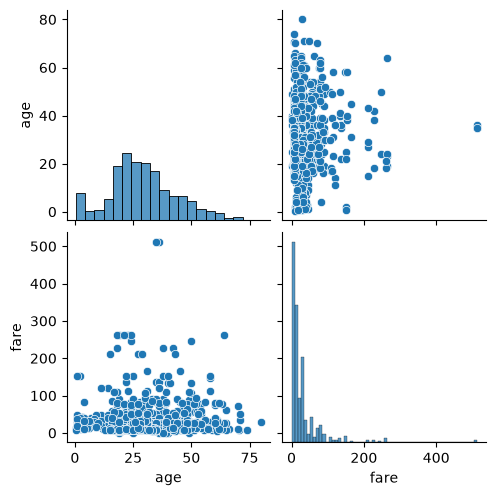

In [6]:
sns.pairplot(df_chosen, vars = ["age", "fare"])
plt.show()

In [7]:
print(df_chosen.shape)      # Number of rows and columns
print(df_chosen.shape[0])   # Number of rows
print(df_chosen.shape[1])   # Number of columns

(891, 9)
891
9


In [8]:
df_chosen.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   cabin     204 non-null    str    
 8   embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 68.7 KB


In [9]:
import warnings
warnings.filterwarnings('ignore')

In [10]:
numerical_columns = df_chosen.select_dtypes(include = "number").columns.tolist()
categorical_columns = df_chosen.select_dtypes(include = ["object", "category"]).columns.tolist()

print(numerical_columns)
print(categorical_columns)

['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
['sex', 'cabin', 'embarked']


In [11]:
missing_count = df_chosen.isnull().sum()

missing_percentage = df_chosen.isnull().mean() * 100

print(missing_count, "\n", missing_percentage)

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
cabin       687
embarked      2
dtype: int64 
 survived     0.000000
pclass       0.000000
sex          0.000000
age         19.865320
sibsp        0.000000
parch        0.000000
fare         0.000000
cabin       77.104377
embarked     0.224467
dtype: float64


In [12]:
df_chosen = df_chosen.drop(columns = ["cabin"])

print(df_chosen.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


In [13]:
median_age = df_chosen["age"].median()

df_chosen["age"] = df_chosen["age"].fillna(median_age)

print("Median age value is ", median_age)
print(df_chosen["age"].isnull().sum())

Median age value is  28.0
0


In [14]:
mode_embarked = df_chosen["embarked"].mode()[0]

df_chosen["embarked"] = df_chosen["embarked"].fillna(mode_embarked)

print("Mode Embarked value is ", mode_embarked)
print(df_chosen["embarked"].isnull().sum())

Mode Embarked value is  S
0


In [15]:
# Checking duplicate records/ rows in the dataset
duplicate_count = df_chosen.duplicated().sum()
print(duplicate_count)

116


In [16]:
df_chosen = df_chosen.drop_duplicates()

df_chosen.info()

<class 'pandas.DataFrame'>
Index: 775 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  775 non-null    int64  
 1   pclass    775 non-null    int64  
 2   sex       775 non-null    str    
 3   age       775 non-null    float64
 4   sibsp     775 non-null    int64  
 5   parch     775 non-null    int64  
 6   fare      775 non-null    float64
 7   embarked  775 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 59.0 KB


In [17]:
df_chosen

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,28.0,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


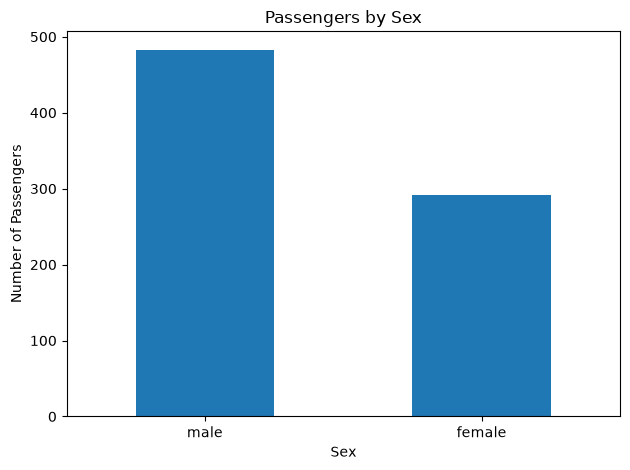

In [19]:
df_chosen["sex"].value_counts().plot(kind = "bar")
plt.title("Passengers by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

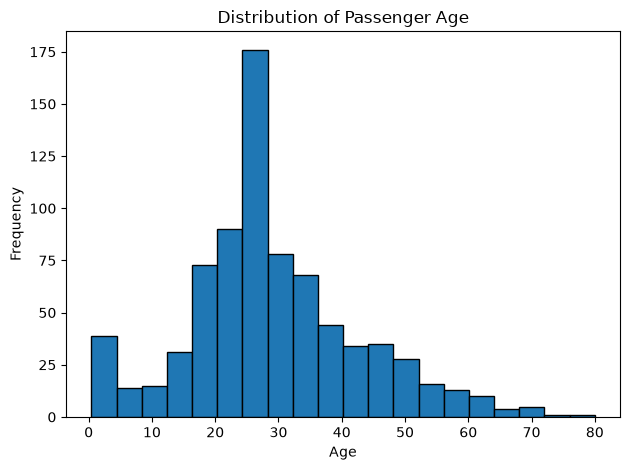

In [20]:
plt.hist(df_chosen["age"], bins = 20, edgecolor = "black")
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

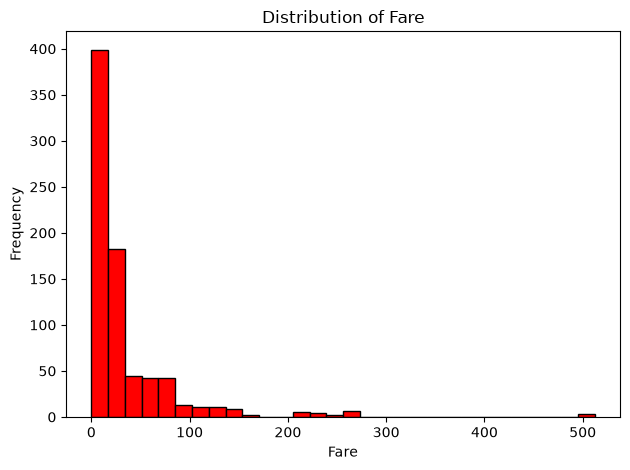

In [23]:
# Draw the histogram for "fare"

plt.hist(df_chosen["fare"], bins = 30, edgecolor = "black", color = "red")
plt.title("Distribution of Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# HeatMap

In [24]:
numerical_df = df_chosen[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']]

correlation_matrix = numerical_df.corr()
correlation_matrix.round(2)

,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.33,-0.08,-0.04,0.07,0.25
pclass,-0.33,1.00,-0.34,0.09,0.04,-0.55
age,-0.08,-0.34,1.00,-0.28,-0.18,0.09
sibsp,-0.04,0.09,-0.28,1.00,0.38,0.13
parch,0.07,0.04,-0.18,0.38,1.00,0.19
fare,0.25,-0.55,0.09,0.13,0.19,1.00


In [ ]:
Interpretation of Strength:
• 0.0 to ± 0.29: Low or weak correlation
• ± 0.30 to ± 0.49: Moderate correlation
• ± 0.50 to ± 1.0: High or strong correlation

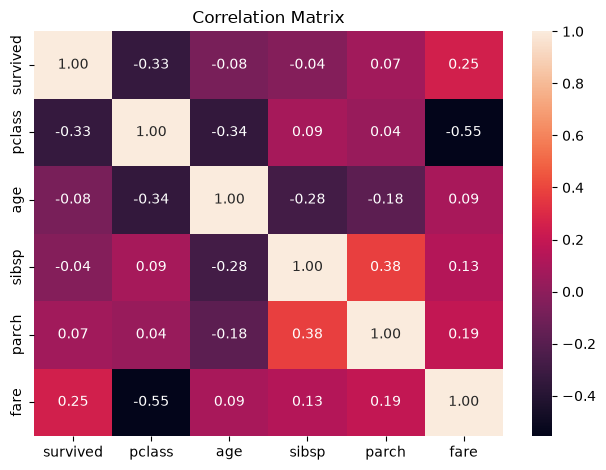

In [26]:
sns.heatmap(correlation_matrix, annot = True, fmt = ".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()